# Imports

In [143]:
import os
import pandas as pd
import numpy as np
from scipy.stats import norm, gaussian_kde
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.gridspec import GridSpec

# Setup

In [140]:
##############################
# Read Dataset into Dataframe
##############################

# path to cleaned dataset
clean_path = r'../data/mnz_cleaned.csv'


# ##### read into df...
# df = pd.read_csv(clean_path)
# df.sort_values('error', inplace=True)
# df.reset_index(inplace=True)
# df.head()



##### read into df...
df = pd.read_csv(clean_path)

##### drop analyses >5% analytical error...
df['percent'] = df['error'] / df['age'] * 100
mask = df['percent'] < 5
df = df.loc[mask]
df.sort_values('error', inplace=True)
df.reset_index(inplace=True)
df.head()

,index,sample,zone,mnz,texture,texture_chem,n,age,error,CaO,...,Dy2O3,Ho2O3,Er2O3,Tm2O3,Yb2O3,SO3,PbO,lree,HREE,percent
0,8,EB14-001,CMZI,m28,overgrowth,Y depleted overgrowth,6.0,348.85,0.701308,0.995224,...,0.181849,0.021200,0.034744,0.069987,0.009827,0.019002,0.097798,60.335048,1.371961,0.201034
1,111,P14-003-2B,MDHSZ,m50,core,Th enriched core,5.0,307.14,0.794103,1.435283,...,0.010042,0.010042,0.010042,0.020180,0.010042,0.018376,0.134090,58.128568,0.677921,0.258548
2,176,P14-005A-5B,CBSZ,m20,core,Y depleted core,NaN,356.00,0.800000,0.827626,...,0.125878,0.009912,0.014868,0.009912,0.009912,0.020815,0.080285,62.602214,1.604702,0.224719
3,114,M1605-2-L3,MDHSZ,m4,rim,Y depleted rim,5.0,298.70,1.381304,0.852869,...,0.062720,0.009927,0.009927,0.009927,0.009927,0.016638,0.084487,62.652220,1.401806,0.462438
4,31,WA14-002,CMZI,m22,rim,Y depleted rim,5.0,353.24,1.461027,0.984389,...,0.079168,0.009819,0.009819,0.061324,0.009819,0.015049,0.087027,61.816443,1.415405,0.413607


# Age Plots

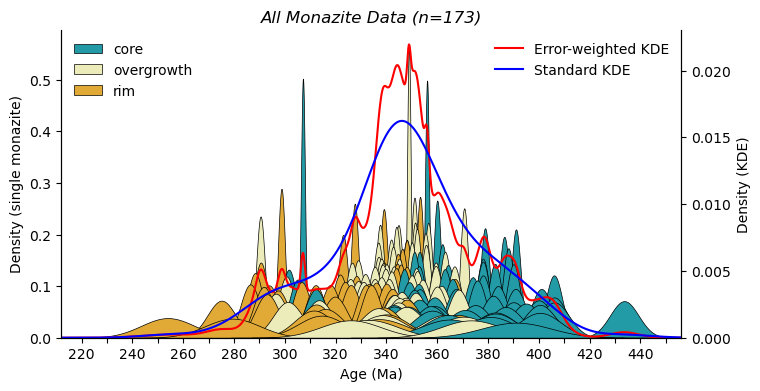

In [141]:
###################################
# Distributions of Ages (All Data)
###################################

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8,4))


##### plot individual PDFs for each monazite analysis...
texture_colors = {'core': '#239BA7', 
                  'overgrowth': '#ECECBB', 
                  'rim': '#E1AA36'}

for idx, row in df.iterrows():
    mean = row['age']
    error = row['error']
    tex = row['texture']
    age_range = np.linspace(mean - 4 * error, mean + 4 * error, 100)
    density = norm.pdf(age_range, mean, error)
    ax.fill_between(age_range, density, alpha=1, color=texture_colors.get(tex), linewidth=0.5, edgecolor='k')

    if mean == df['age'].min():
        xmin = age_range.min()
    if mean == df['age'].max():
        xmax = age_range.max()


##### plot KDEs...
ages = df['age'].to_numpy()
errors = df['error'].to_numpy()
t = np.linspace(xmin, xmax, 1000)

# error-weighted KDE...
density_err = np.zeros_like(t)
for age, err in zip(ages, errors):
    density_err += np.exp(-(t-age)**2 / (2*err**2)) / (np.sqrt(2*np.pi)*err)
density_err /= len(ages)

# standard KDE...
kde = gaussian_kde(ages)
density_std = kde(t)

# plot KDEs...
ax2 = ax.twinx()
ax2.plot(t, density_err, color='red', label='Error-weighted KDE')
ax2.plot(t, density_std, color='blue', label='Standard KDE')


##### legend...
ax1_patches = []
for k,v in texture_colors.items():
    ax1_patches.append(Patch(facecolor=v, edgecolor='k', linewidth=0.5, label=k))
ax.legend(ax1_patches, [lab.get_label() for lab in ax1_patches], loc='upper left', bbox_to_anchor=(0,1), frameon=False)
ax2.legend(loc='upper right', bbox_to_anchor=(1,1), frameon=False)


##### figure styling...
ax.set_xlim(xmin, xmax)
ax.set_xticks(np.arange(220, 451, 10))
ax.set_xticklabels([str(i) if i%20 == 0 else '' for i in np.arange(220, 451, 10)])
ax.set_xlabel('Age (Ma)')
ax.set_ylim(0)
ax2.set_ylim(0)

ax.set_ylabel('Density (single monazite)')
ax2.set_ylabel('Density (KDE)')

ax.set_title(f"All Monazite Data (n={len(df)})", style='italic')
ax.spines['top'].set_visible(False)
ax2.spines['top'].set_visible(False)

# plt.savefig('all_ages.png', bbox_inches="tight", pad_inches=0, dpi=300)
plt.show()

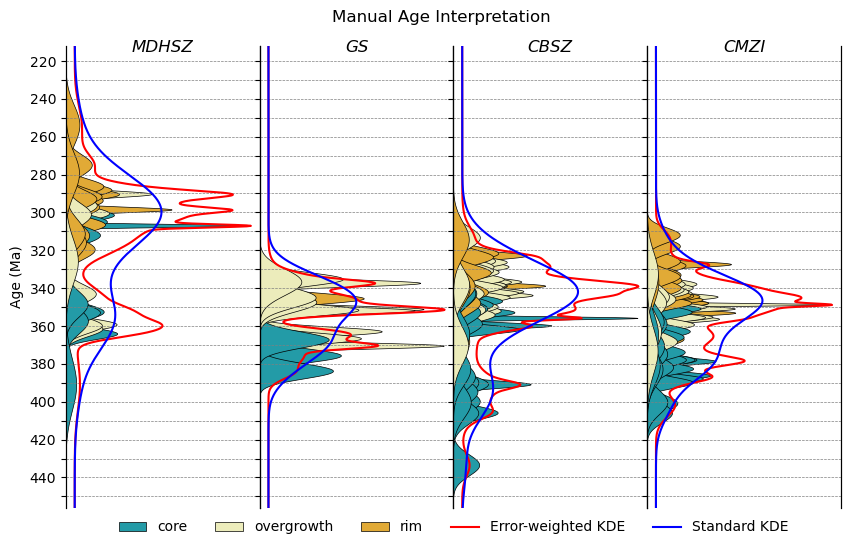

In [142]:
##########################################
# Distributions of Ages by Structural Zone
##########################################

# list of structural tectonic zones west to east
structural_zones = ['MDHSZ', 'GS', 'CBSZ', 'CMZI']

# dictionary color mapperr for texture categoriess
texture_colors = {'core': '#239BA7', 
                  'overgrowth': '#ECECBB', 
                  'rim': '#E1AA36'}


##### create plots...
fig, ax = plt.subplots(nrows=1, ncols=4, sharey=True, figsize=(10,6))
plt.subplots_adjust(wspace=0)


##### iterate through structural tectonic zones...
for idx, zone in enumerate(structural_zones):

    # extract subset df
    df_subset = df[df['zone'] == zone].copy()

    # title for plot
    ax[idx].set_title(zone, style='italic', y=0.97)
    

    ##### individual PDFs for each monazite analysis...
    for _, row in df_subset.iterrows():
        mean = row['age']
        error = row['error']
        tex = row['texture']
        age_range = np.linspace(mean - 4 * error, mean + 4 * error, 100)
        density = norm.pdf(age_range, mean, error)
        ax[idx].fill_between(density, age_range, alpha=1, color=texture_colors.get(tex), linewidth=0.5, edgecolor='k')


    ##### KDEs...
    ages = df_subset['age'].to_numpy()
    errors = df_subset['error'].to_numpy()
    t = np.linspace(210, 460, 1000)

    # error-weighted KDE...
    density_err = np.zeros_like(t)
    for age, err in zip(ages, errors):
        density_err += np.exp(-(t-age)**2 / (2*err**2)) / (np.sqrt(2*np.pi)*err)
    density_err /= len(ages)

    # standard KDE...
    kde = gaussian_kde(ages)
    density_std = kde(t)

    # plot KDEs...
    ax2 = ax[idx].twiny()
    ax2.plot(density_err, t, color='red', label='Error-weighted KDE')
    ax2.plot(density_std, t, color='blue', label='Standard KDE')
    ax2.set_xticks([])
    ax2.spines['top'].set_visible(False)
    ax2.spines['bottom'].set_visible(False)


##### legend...
patches = []
for k,v in texture_colors.items():
    patches.append(Patch(facecolor=v, edgecolor='k', linewidth=0.5, label=k))
lines = [Line2D([0], [0], color='red', label='Error-weighted KDE'), 
         Line2D([0], [0], color='blue', label='Standard KDE')]
legend_items = patches + lines
ax[0].legend(legend_items, [l.get_label() for l in legend_items], loc='upper center', bbox_to_anchor=(2,0), frameon=False, ncols=5)


##### figure styling...
min_idx = df['age'].argmin()
max_idx = df['age'].argmax()
age_min = df.loc[min_idx, 'age'] - 4 * df.loc[min_idx, 'error']
age_max = df.loc[max_idx, 'age'] + 4 * df.loc[max_idx, 'error']
for axes in ax:
    axes.set_xlim(0)
    axes.set_ylim(age_min, age_max)
    axes.grid(visible=True, axis='y', linestyle='--', color='gray', linewidth=0.5)
    axes.set_xticks([])

    axes.spines['top'].set_visible(False)
    axes.spines['bottom'].set_visible(False)

ax[0].set_yticks(np.arange(220, 451, 10))
ax[0].set_yticklabels([str(i) if i%20 == 0 else '' for i in np.arange(220, 451, 10)])
ax[0].set_ylabel('Age (Ma)')

plt.gca().invert_yaxis()
plt.suptitle('Manual Age Interpretation', y=0.94)

# plt.savefig('all_ages.png', bbox_inches="tight", pad_inches=0, dpi=300)
plt.show()

In [144]:
def plot_triplet(df, subname, ax1, ax2, ax3, color_map, label_bool=True, timeline=[210, 450], xlabels=['Density', 'Density', 'Y2O3 (Wt. %)'], ylabels='Age (Ma)'):

    # (1) Individual Gaussian curves (density vs age)
    sample_max = 0.
    for _, row in df.iterrows():
        mean = row['age']
        error = row['error']
        tex = row['texture']
        age_range = np.linspace(mean - 4 * error, mean + 4 * error, 100)
        density = norm.pdf(age_range, mean, error)
        sample_max = max(sample_max, density.max())
        ax1.fill_between(density, age_range, alpha=1, color=texture_colors.get(tex), linewidth=0.5, edgecolor='k')
    
    ax1.set_xlim(0, sample_max+0.01)
    ax1.set_xticks([])
    ax1.set_yticks(np.arange(210, 451, 10))
    ax1.set_yticklabels([str(i) if i%20 == 0 else '' for i in np.arange(210, 451, 10)])
    ax1.invert_yaxis()
    ax1.tick_params(axis='y', which='major', labelleft=label_bool)
    if label_bool:
        ax1.set_ylabel(ylabels)
    else:
        ax1.set_ylabel(None)
    ax1.grid(which='major', axis='y', color='gray', alpha=1, ls="--")
    


    # (2) KDE (density vs age)
    ages = df['age'].to_numpy()
    errors = df['error'].to_numpy()
    t = np.linspace(timeline[0], timeline[-1], 1000)

    # standard KDE...
    kde = gaussian_kde(ages)
    density_std = kde(t)
    ax2.plot(density_std, t, color='blue', label='Standard KDE')
    ax2.set_xlim(0., density_std.max()+0.001)
    ax2.set_xticks([])
    ax2.set_ylim(timeline[0], timeline[1])
    ax2.invert_yaxis()
    ax2.tick_params(axis='y', which='major', length=0.0001, labelleft=False)
    ax2.grid(axis='y', color='gray', alpha=1, ls='--')

    # error-weighted KDE...
    density_err = np.zeros_like(t)
    for age, err in zip(ages, errors):
        density_err += np.exp(-(t-age)**2 / (2*err**2)) / (np.sqrt(2*np.pi)*err)
    density_err /= len(ages)
    ax2b = ax2.twinx()
    ax2b.plot(density_err, t, color='red', label='Error-weighted KDE')
    ax2b.set_xlim(0., density_err.max()+0.001)
    ax2b.set_axis_off()
    ax2b.invert_yaxis()

    


    # (3) Y2O3 vs age
    ax3.plot(df["Y2O3"], df["age"], marker='o', markeredgecolor='k', markeredgewidth=0.3, linewidth=0, alpha=0.5)
    ax3.set_xlim(df['Y2O3'].min() - 0.3, df['Y2O3'].max() + 0.3)
    ax3.set_xticks([])
    ax3.set_ylim(timeline[0], timeline[1])
    ax3.invert_yaxis()
    ax3.tick_params(axis='y', which='major', length=0.0001, labelleft=False)
    ax3.grid(axis='y', color='gray', alpha=1, ls='--')


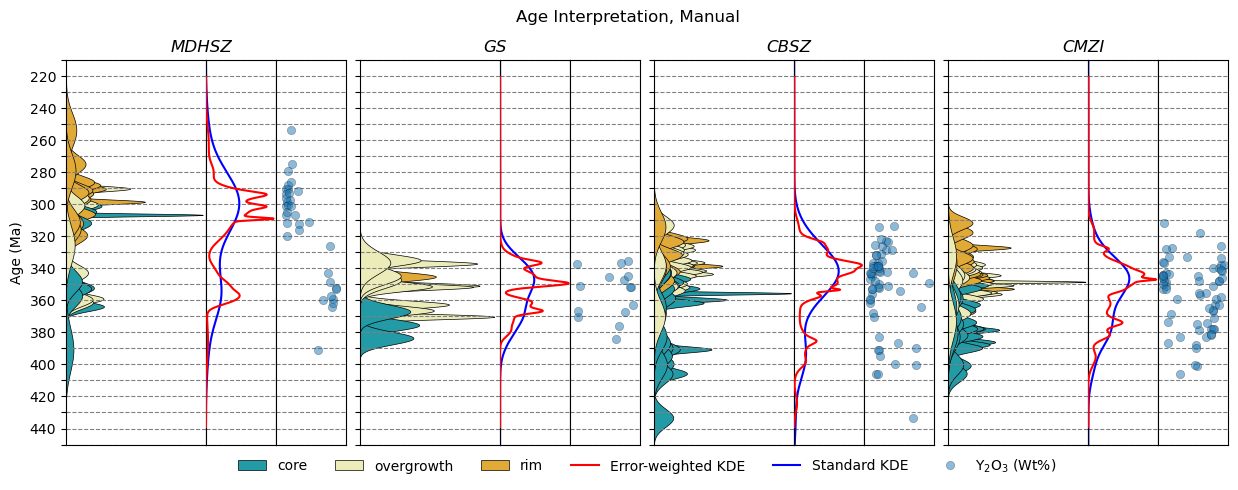

In [145]:


# list of structural tectonic zones west to east
structural_zones = ['MDHSZ', 'GS', 'CBSZ', 'CMZI']

# dictionary color mapperr for texture categoriess
texture_colors = {'core': '#239BA7', 
                  'overgrowth': '#ECECBB', 
                  'rim': '#E1AA36'}

# ---- figure: 1 row, 7 columns (3 + spacer + 3) ----
fig = plt.figure(figsize=(15, 5))
gs = GridSpec(nrows=1, ncols=15, figure=fig, width_ratios=[1.0, 0.5, 0.5, 0.1, 1.0, 0.5, 0.5, 0.1, 1.0, 0.5, 0.5, 0.1, 1.0, 0.5, 0.5], wspace=0)

# axes: left triplet (A), spacer (hidden), right triplet (B)
axA_a = fig.add_subplot(gs[0, 0])
axA_b = fig.add_subplot(gs[0, 1], sharey=axA_a)
axA_c = fig.add_subplot(gs[0, 2], sharey=axA_a)
ax_sp1 = fig.add_subplot(gs[0, 3])  # spacer
axB_a = fig.add_subplot(gs[0, 4], sharey=axA_a)
axB_b = fig.add_subplot(gs[0, 5], sharey=axA_a)
axB_c = fig.add_subplot(gs[0, 6], sharey=axA_a)
ax_sp2 = fig.add_subplot(gs[0, 7])  # spacer
axC_a = fig.add_subplot(gs[0, 8], sharey=axA_a)
axC_b = fig.add_subplot(gs[0, 9], sharey=axA_a)
axC_c = fig.add_subplot(gs[0, 10], sharey=axA_a)
ax_sp3 = fig.add_subplot(gs[0, 11])  # spacer
axD_a = fig.add_subplot(gs[0, 12], sharey=axA_a)
axD_b = fig.add_subplot(gs[0, 13], sharey=axA_a)
axD_c = fig.add_subplot(gs[0, 14], sharey=axA_a)

# hide spacer axis
ax_sp1.axis("off")
ax_sp2.axis("off")
ax_sp3.axis("off")


for idx, zone in enumerate(structural_zones):
    df_subset = df.loc[df['zone']==zone].copy()

    if idx==0:
        plot_triplet(df_subset, zone, axA_a, axA_b, axA_c, texture_colors, label_bool=True)
        axA_b.set_title(zone, style='italic', loc='center', x=-0.071)
    elif idx==1:
        plot_triplet(df_subset, zone, axB_a, axB_b, axB_c, texture_colors, label_bool=False)
        axB_b.set_title(zone, style='italic', loc='center', x=-0.071)
    elif idx==2:
        plot_triplet(df_subset, zone, axC_a, axC_b, axC_c, texture_colors, label_bool=False)
        axC_b.set_title(zone, style='italic', loc='center', x=-0.071)
    else:
        plot_triplet(df_subset, zone, axD_a, axD_b, axD_c, texture_colors, label_bool=False)
        axD_b.set_title(zone, style='italic', loc='center', x=-0.071)
    

##### legend...
patches = []
for k,v in texture_colors.items():
    patches.append(Patch(facecolor=v, edgecolor='k', linewidth=0.5, label=k))

lines = [Line2D([0], [0], color='red', label='Error-weighted KDE'), 
         Line2D([0], [0], color='blue', label='Standard KDE')]

points = [Line2D([0], [0], marker='o', markeredgecolor='k', markeredgewidth=0.3, linewidth=0, alpha=0.5, label=r"$\mathrm{Y_{2}O_{3}}$ (Wt%)")]

legend_items = patches + lines + points
ax_sp2.legend(legend_items, [l.get_label() for l in legend_items], loc='upper center', bbox_to_anchor=(0.5,0), frameon=False, ncols=6)

    
plt.suptitle('Age Interpretation, Manual')
plt.show()